# Revised model development with a fixed validation set

This notebook develops LightGBM regression models using the selected feature set from `feature_engineering.ipynb` for the split named by `SPLIT_SCHEME`. Hyperparameters are optimized with `BayesSearchCV` using one predefined train/validation split. The test set is not loaded or used in this notebook.

Separate models are developed for the low-MP (`L`), high-MP (`H`), and all-compound (`All`) regimes. `TRAINING_VARIANT` selects the training table: the full training set, the Low-MP undersampled set, or the balanced Low+High set from `prepare_low_MP_undersampled.ipynb`. Models are saved to `revised_models/<SPLIT_SCHEME>/<run name>/`. The final refit mode is configurable and can use either training data only or training plus validation data after model decisions are frozen.

In [1]:
from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import PredefinedSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
from skopt import BayesSearchCV
from skopt.space import Real, Integer

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or a project subdirectory.')

SPLIT_SCHEME = 'stereo_cleaned'  # folder written by 1_data_split/data_split.ipynb
FEATURE_VARIANT = 'correlation_selected'  # the feature set from feature_engineering.ipynb
TRAINING_VARIANT = 'full'
# Training options: 'full', 'low_MP_undersampled', or 'balanced_low_high'.
FEATURE_ROOT = PROJECT_ROOT / '2_feature_engineering' / 'outputs' / SPLIT_SCHEME
if FEATURE_VARIANT != 'correlation_selected':
    raise ValueError(f'Unsupported FEATURE_VARIANT: {FEATURE_VARIANT}')
SELECTED_DIR = FEATURE_ROOT / 'selected_features'
FEATURE_LIST_PATH = FEATURE_ROOT / 'selected_features.csv'
TRAIN_FILENAME = 'train_selected_features.parquet'
VALIDATION_FILENAME = 'validation_selected_features.parquet'

if TRAINING_VARIANT == 'low_MP_undersampled':
    UNDERSAMPLED_DIR = FEATURE_ROOT / 'low_MP_undersampled'
    TRAIN_PATH = UNDERSAMPLED_DIR / 'train_low_MP_undersampled.parquet'
    VALIDATION_PATH = UNDERSAMPLED_DIR / 'validation_full.parquet'
    MODEL_RUN_NAME = 'low_MP_undersampled'
    DATA_TYPES = ['L']
elif TRAINING_VARIANT == 'balanced_low_high':
    BALANCED_DIR = FEATURE_ROOT / 'balanced_low_high'
    TRAIN_PATH = BALANCED_DIR / 'train_balanced_low_high.parquet'
    # Use the original full validation population, unchanged.
    VALIDATION_PATH = SELECTED_DIR / VALIDATION_FILENAME
    MODEL_RUN_NAME = 'balanced_low_high'
    DATA_TYPES = ['L', 'H', 'All']
elif TRAINING_VARIANT == 'full':
    TRAIN_PATH = SELECTED_DIR / TRAIN_FILENAME
    VALIDATION_PATH = SELECTED_DIR / VALIDATION_FILENAME
    MODEL_RUN_NAME = FEATURE_VARIANT
    DATA_TYPES = ['L', 'H', 'All']
else:
    raise ValueError(f'Unsupported TRAINING_VARIANT: {TRAINING_VARIANT}')
MODEL_OUTPUT_DIR = PROJECT_ROOT / '3_model_development' / 'revised_models' / SPLIT_SCHEME / MODEL_RUN_NAME
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
HPO_OUTPUT_DIR = MODEL_OUTPUT_DIR / 'hyperparameter_optimization' / RUN_ID
HPO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_TYPES = ['LGB']
MP_COLUMN = 'MP'
CLASS_COLUMN = 'MP_class'
RANDOM_STATE = 2026
N_BAYES_TRIALS = 20
FINAL_FIT_MODE = 'train_plus_validation'

print('Split scheme:', SPLIT_SCHEME)
print('Feature variant:', FEATURE_VARIANT)
print('Training variant:', TRAINING_VARIANT)
print('Training input:', TRAIN_PATH.relative_to(PROJECT_ROOT))
print('Validation input:', VALIDATION_PATH.relative_to(PROJECT_ROOT))
print('Model output directory:', MODEL_OUTPUT_DIR.relative_to(PROJECT_ROOT))
print('HPO archive directory:', HPO_OUTPUT_DIR.relative_to(PROJECT_ROOT))
print('Model types:', MODEL_TYPES)
print('Data regimes:', DATA_TYPES)

Split scheme: stereo_cleaned
Feature variant: correlation_selected
Training variant: full
Training input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/train_selected_features.parquet
Validation input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/validation_selected_features.parquet
Model output directory: 3_model_development/revised_models/stereo_cleaned/correlation_selected
HPO archive directory: 3_model_development/revised_models/stereo_cleaned/correlation_selected/hyperparameter_optimization/20261102_044049
Model types: ['LGB']
Data regimes: ['L', 'H', 'All']


## Load the selected features

Only the train and validation tables are loaded. The feature list is used explicitly so metadata cannot accidentally enter the model matrix.

In [2]:
if not FEATURE_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing selected feature list: {FEATURE_LIST_PATH}')

feature_names = pd.read_csv(FEATURE_LIST_PATH)['Feature'].dropna().astype(str).tolist()
train_data = pd.read_parquet(TRAIN_PATH)
validation_data = pd.read_parquet(VALIDATION_PATH)

required_metadata = {MP_COLUMN, CLASS_COLUMN}
for split_name, frame in {'train': train_data, 'validation': validation_data}.items():
    missing_features = sorted(set(feature_names).difference(frame.columns))
    missing_metadata = sorted(required_metadata.difference(frame.columns))
    if missing_features or missing_metadata:
        raise ValueError(f'{split_name}: missing features={missing_features[:5]}, missing metadata={missing_metadata}')
    if frame[feature_names].isna().any().any():
        raise ValueError(f'{split_name} contains NaN values in selected features.')

if TRAINING_VARIANT == 'low_MP_undersampled' and not train_data[CLASS_COLUMN].astype(str).str.strip().str.lower().eq('low').all():
    raise ValueError('The undersampled training table must contain only Low-MP rows.')

print('Train shape:', train_data.shape)
print('Validation shape:', validation_data.shape)
print('Selected features:', len(feature_names))
display(train_data[CLASS_COLUMN].value_counts().rename_axis(CLASS_COLUMN).to_frame('count'))

def regime_mask(frame, regime):
    if regime == 'All':
        return pd.Series(True, index=frame.index)
    target = {'L': 'low', 'H': 'high'}.get(regime)
    if target is None:
        raise ValueError(f'Unsupported regime: {regime}')
    normalized = frame[CLASS_COLUMN].astype(str).str.strip().str.lower()
    return normalized.eq(target)

Train shape: (166280, 1711)
Validation shape: (55427, 1711)
Selected features: 1690


,count
MP_class,
low,153434
high,12846


## Model definition and fixed-validation Bayesian search

`PredefinedSplit` marks training rows with `-1` and validation rows with `0`. Consequently, every `BayesSearchCV` trial is fitted on the training subset and evaluated once on the same fixed validation subset. This is not 10-fold cross-validation.

The LightGBM search space (parameters, ranges and priors) and the number of Bayesian trials are the same as in the original `model_development.ipynb`, so the original and revised workflows are tuned identically. As in the original, `subsample_freq` is left at its default of 0, so the sampled `subsample` value does not change the fitted model.

In [3]:
def model_definition(model_type):
    if model_type == 'LGB':
        estimator = lgb.LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1)
        search_space = {
            'num_leaves': Integer(20, 300),
            'max_depth': Integer(3, 12),
            'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
            'n_estimators': Integer(20, 500),
            'min_child_samples': Integer(10, 50),
            'subsample': Real(0.6, 1.0),
            'colsample_bytree': Real(0.4, 1.0),
            'reg_alpha': Real(1e-5, 10.0, prior='log-uniform'),
            'reg_lambda': Real(1e-5, 10.0, prior='log-uniform'),
        }
    else:
        raise ValueError(f'Unsupported model type: {model_type}')
    return estimator, search_space

def native_params(params):
    # BayesSearchCV returns numpy scalars; store plain Python numbers.
    return {str(key): value.item() if hasattr(value, 'item') else value for key, value in params.items()}

def make_regression_metrics(y_true, prediction):
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, prediction))),
        'MAE': float(mean_absolute_error(y_true, prediction)),
        'R2': float(r2_score(y_true, prediction)),
    }

def fixed_validation_search(train_subset, validation_subset, model_type):
    X_train = train_subset[feature_names]
    y_train = train_subset[MP_COLUMN].to_numpy()
    X_validation = validation_subset[feature_names]
    y_validation = validation_subset[MP_COLUMN].to_numpy()

    X_search = pd.concat([X_train, X_validation], ignore_index=True)
    y_search = np.concatenate([y_train, y_validation])
    test_fold = np.concatenate([
        np.full(len(X_train), -1, dtype=int),
        np.zeros(len(X_validation), dtype=int),
    ])
    fixed_split = PredefinedSplit(test_fold=test_fold)

    default_model, search_space = model_definition(model_type)
    default_model.fit(X_train, y_train)
    default_metrics = make_regression_metrics(y_validation, default_model.predict(X_validation))

    optimizer_model, _ = model_definition(model_type)
    search = BayesSearchCV(
        estimator=optimizer_model,
        search_spaces=search_space,
        n_iter=N_BAYES_TRIALS,
        cv=fixed_split,
        scoring='neg_root_mean_squared_error',
        random_state=RANDOM_STATE,
        n_jobs=1,
        refit=False,
    )
    search.fit(X_search, y_search)

    trial_rows = []
    for trial_index, (params, score) in enumerate(zip(search.cv_results_['params'], search.cv_results_['split0_test_score'])):
        trial_rows.append({
            'Trial': trial_index + 1,
            'Validation_RMSE': float(-score),
            'Parameters': json.dumps(native_params(params), sort_keys=True),
        })
    trial_results = pd.DataFrame(trial_rows).sort_values('Validation_RMSE').reset_index(drop=True)
    best_params = native_params(search.best_params_)

    return {
        'default_metrics': default_metrics,
        'trial_results': trial_results,
        'best_params': best_params,
    }

## Run model development for `L`, `H`, and `All`

The `L` and `H` models are useful for regime-specific analysis. The `All` model is the general-purpose regression model. Because the true MP class is unavailable for an unknown compound, using the `L`/`H` models for deployment would require a separate routing classifier.

In [4]:
all_results = {}

for model_type in MODEL_TYPES:
    for data_type in DATA_TYPES:
        train_subset = train_data.loc[regime_mask(train_data, data_type)].reset_index(drop=True)
        validation_subset = validation_data.loc[regime_mask(validation_data, data_type)].reset_index(drop=True)

        if len(train_subset) < 10 or len(validation_subset) < 5:
            raise ValueError(f'{data_type} subset is too small: train={len(train_subset)}, validation={len(validation_subset)}')

        key = f'{model_type}_{data_type}'
        print(f'\n=== {key} ===')
        print(f'Train compounds: {len(train_subset):,}; validation compounds: {len(validation_subset):,}')
        result = fixed_validation_search(train_subset, validation_subset, model_type)
        all_results[key] = result

        result['trial_results'].to_csv(MODEL_OUTPUT_DIR / f'trial_results_{key}.csv', index=False)
        (MODEL_OUTPUT_DIR / f'best_params_{key}.json').write_text(json.dumps(result['best_params'], indent=2))
        with open(MODEL_OUTPUT_DIR / f'development_summary_{key}.pkl', 'wb') as handle:
            pickle.dump({'default_metrics': result['default_metrics'], 'best_params': result['best_params'], 'best_validation_row': result['trial_results'].iloc[0].to_dict()}, handle)

        # Archive every HPO run separately so later notebook runs do not erase history.
        result['trial_results'].to_csv(HPO_OUTPUT_DIR / f'trial_results_{key}.csv', index=False)
        (HPO_OUTPUT_DIR / f'best_params_{key}.json').write_text(json.dumps(result['best_params'], indent=2))
        hpo_summary = {
            'run_id': RUN_ID,
            'split_scheme': SPLIT_SCHEME,
            'feature_variant': FEATURE_VARIANT,
            'training_variant': TRAINING_VARIANT,
            'model_type': model_type,
            'data_regime': data_type,
            'n_bayes_trials': N_BAYES_TRIALS,
            'train_compounds': len(train_subset),
            'validation_compounds': len(validation_subset),
            'default_validation_metrics': result['default_metrics'],
            'best_params': result['best_params'],
            'best_validation_row': result['trial_results'].iloc[0].to_dict(),
        }
        (HPO_OUTPUT_DIR / f'hpo_summary_{key}.json').write_text(json.dumps(hpo_summary, indent=2, default=str))
        summary_text = [
            f'=== {key} ===',
            f'Train compounds: {len(train_subset):,}; validation compounds: {len(validation_subset):,}',
            f'Default validation metrics: {result["default_metrics"]}',
            f'Best parameters: {result["best_params"]}',
            '',
            'Best Bayesian-search row:',
            result['trial_results'].head(1).to_string(index=False),
        ]
        (HPO_OUTPUT_DIR / f'hpo_summary_{key}.txt').write_text('\n'.join(summary_text))

        print('Default validation metrics:', result['default_metrics'])
        print('Best parameters:', result['best_params'])
        print('Best Bayesian-search row:')
        display(result['trial_results'].head(1))


=== LGB_L ===
Train compounds: 153,434; validation compounds: 51,145


Default validation metrics: {'RMSE': 36.636270929084354, 'MAE': 28.868393259174915, 'R2': 0.5215631682313449}
Best parameters: {'colsample_bytree': 0.4, 'learning_rate': 0.05512753377756557, 'max_depth': 12, 'min_child_samples': 21, 'n_estimators': 500, 'num_leaves': 300, 'reg_alpha': 0.01582182294178147, 'reg_lambda': 1e-05, 'subsample': 0.6}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,13,33.842865,"{""colsample_bytree"": 0.4, ""learning_rate"": 0.0..."



=== LGB_H ===
Train compounds: 12,846; validation compounds: 4,282


Default validation metrics: {'RMSE': 23.122715017642086, 'MAE': 17.687740067248228, 'R2': 0.22683309547275832}
Best parameters: {'colsample_bytree': 0.7363796353366491, 'learning_rate': 0.022731314142612313, 'max_depth': 12, 'min_child_samples': 50, 'n_estimators': 500, 'num_leaves': 291, 'reg_alpha': 0.7653007582806595, 'reg_lambda': 0.25814379833700807, 'subsample': 0.9811640699533658}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,14,22.677822,"{""colsample_bytree"": 0.7363796353366491, ""lear..."



=== LGB_All ===
Train compounds: 166,280; validation compounds: 55,427


Default validation metrics: {'RMSE': 40.83191342553457, 'MAE': 31.486642815632532, 'R2': 0.5812064643071144}
Best parameters: {'colsample_bytree': 0.5586619020762866, 'learning_rate': 0.0622179657722014, 'max_depth': 12, 'min_child_samples': 50, 'n_estimators': 484, 'num_leaves': 300, 'reg_alpha': 10.0, 'reg_lambda': 1e-05, 'subsample': 0.7242881847905911}
Best Bayesian-search row:


,Trial,Validation_RMSE,Parameters
0,20,37.176192,"{""colsample_bytree"": 0.5586619020762866, ""lear..."


Saved hyperparameter-search figure to 3_model_development/revised_models/stereo_cleaned/correlation_selected/hyperparameter_optimization/20261102_044049/hyperparameter_search_LGB_L.png


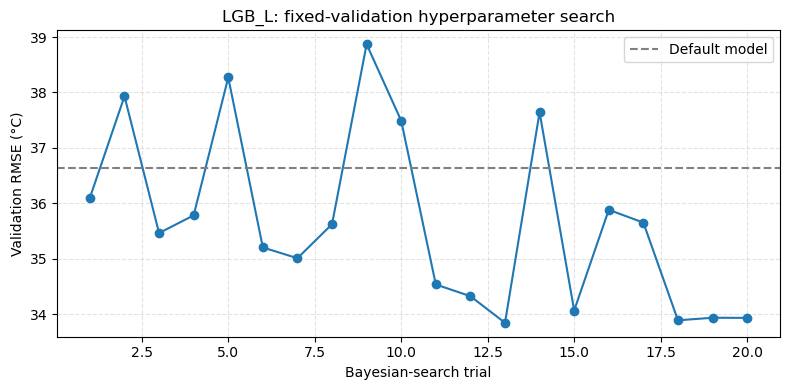

Saved hyperparameter-search figure to 3_model_development/revised_models/stereo_cleaned/correlation_selected/hyperparameter_optimization/20261102_044049/hyperparameter_search_LGB_H.png


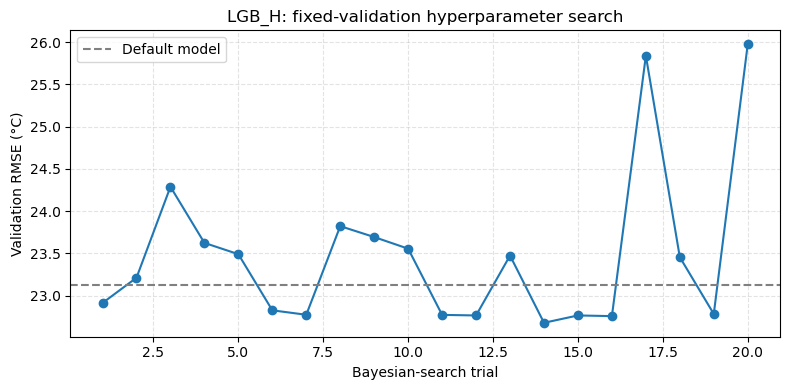

Saved hyperparameter-search figure to 3_model_development/revised_models/stereo_cleaned/correlation_selected/hyperparameter_optimization/20261102_044049/hyperparameter_search_LGB_All.png


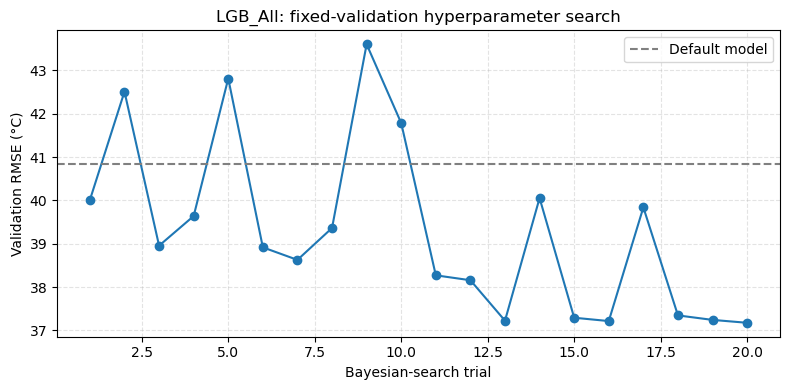

In [5]:
import matplotlib.pyplot as plt

for key, result in all_results.items():
    trials = result['trial_results'].sort_values('Trial')
    plt.figure(figsize=(8, 4))
    plt.plot(trials['Trial'], trials['Validation_RMSE'], marker='o')
    plt.axhline(result['default_metrics']['RMSE'], color='grey', linestyle='--', label='Default model')
    plt.xlabel('Bayesian-search trial')
    plt.ylabel('Validation RMSE (°C)')
    plt.title(f'{key}: fixed-validation hyperparameter search')
    plt.grid(True, linestyle='--', alpha=0.35)
    plt.legend()
    plt.tight_layout()
    figure_path = HPO_OUTPUT_DIR / f'hyperparameter_search_{key}.png'
    plt.savefig(figure_path, dpi=200, bbox_inches='tight')
    print(f'Saved hyperparameter-search figure to {figure_path.relative_to(PROJECT_ROOT)}')
    plt.show()

## Fit and save the final models

After fixed-validation hyperparameter selection, each model is refit with its selected hyperparameters according to `FINAL_FIT_MODE`. With `train_plus_validation`, the training rows of the regime are combined with the regime's full validation subset. The test set is not loaded or used here.

For the `low_MP_undersampled` and `balanced_low_high` variants, the final model is refit on the variant's training table plus the regime's full validation subset, as in the earlier revised models. The saved metadata records the number of training and validation rows used.

In [6]:
final_models = {}
for key, result in all_results.items():
    model_type, data_type = key.rsplit('_', 1)
    train_subset = train_data.loc[regime_mask(train_data, data_type)].reset_index(drop=True)
    validation_subset = validation_data.loc[regime_mask(validation_data, data_type)].reset_index(drop=True)
    if FINAL_FIT_MODE == 'train_plus_validation':
        fit_data = pd.concat([train_subset, validation_subset], ignore_index=True)
    elif FINAL_FIT_MODE == 'train_only':
        fit_data = train_subset
    else:
        raise ValueError(f'Unsupported FINAL_FIT_MODE: {FINAL_FIT_MODE}')
    final_model, _ = model_definition(model_type)
    final_model.set_params(**result['best_params'])
    final_model.fit(fit_data[feature_names], fit_data[MP_COLUMN].to_numpy())
    model_path = MODEL_OUTPUT_DIR / f'best_model_{key}_{FINAL_FIT_MODE}.joblib'
    joblib.dump(final_model, model_path)
    metadata = {
        'split_scheme': SPLIT_SCHEME,
        'feature_variant': FEATURE_VARIANT,
        'training_variant': TRAINING_VARIANT,
        'model_type': model_type,
        'data_regime': data_type,
        'final_fit_mode': FINAL_FIT_MODE,
        'train_rows_used': int(len(train_subset)),
        'validation_rows_used': int(len(validation_subset)),
        'final_fit_rows': int(len(fit_data)),
        'selected_feature_count': int(len(feature_names)),
        'random_state': RANDOM_STATE,
        'test_used': False,
    }
    (MODEL_OUTPUT_DIR / f'model_metadata_{key}_{FINAL_FIT_MODE}.json').write_text(json.dumps(metadata, indent=2))
    final_models[key] = final_model
    print(f'Saved {key}: {model_path.relative_to(PROJECT_ROOT)}')
    print(f'  final-fit rows: {len(fit_data):,} (train={len(train_subset):,}, validation={len(validation_subset):,})')

Saved LGB_L: 3_model_development/revised_models/stereo_cleaned/correlation_selected/best_model_LGB_L_train_plus_validation.joblib
  final-fit rows: 204,579 (train=153,434, validation=51,145)


Saved LGB_H: 3_model_development/revised_models/stereo_cleaned/correlation_selected/best_model_LGB_H_train_plus_validation.joblib
  final-fit rows: 17,128 (train=12,846, validation=4,282)


Saved LGB_All: 3_model_development/revised_models/stereo_cleaned/correlation_selected/best_model_LGB_All_train_plus_validation.joblib
  final-fit rows: 221,707 (train=166,280, validation=55,427)
